# Task 6 - Benchmark and discuss the tradeoffs

In [1]:
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.flop_counter import FlopCounterMode
from torchvision.transforms import v2 as T
from torchvision.transforms.v2 import functional as F

from cifar_data import CLASS_NAMES, get_split, load_cifar10, prepare_inputs
from models.alexnet import AlexNet
from models.resnet import ResNet18
from train import CHECKPOINT_DIR, Run, count_parameters, evaluate, get_device, run_experiment

RECOMPUTE = False   # True = measure everything again even if the csvs in results/ already exist
QUICK = False       # True = fewer timing repeats, only for a quick test run (not for the report)
FIG_DIR = Path("figures/task6"); FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

device = get_device()
NUM_WORKERS = 2 if device.type == "cuda" else 0
# same cudnn settings as in training (set_seed uses deterministic=True) so the timings match
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

data = load_cifar10()
split = get_split(data["train"])
stats = split["stats"]
N_TRAIN = len(split["train_ids"])

HARDWARE = torch.cuda.get_device_name(0) if device.type == "cuda" else (platform.processor() or platform.machine())
print("torch", torch.__version__, "| device", device, "|", HARDWARE, "| CPU threads", torch.get_num_threads())

torch 2.15.0+cu132 | device cuda | NVIDIA GeForce RTX 3060 Laptop GPU | CPU threads 8


## Which configurations and what budget?

Our budget from Task 2 is 15 epochs x 45k images = 675k training samples per model, with batch size 128, SGD + momentum, cosine schedule and the best val epoch kept. AlexNet uses lr 0.01 and ResNet 0.1.

Each run has a reference run that it gets compared to, e.g. augmentation vs the baseline of the same model. The AlexNet runs with 30-40 epochs are over budget, but they're still useful for the training length question. The dropout runs are compared with each other since they all have 30 epochs.

`resnet18_l2_0.0005` from Task 3 is the exact same setup as `resnet18_baseline`, so it's left out here and only used for the reproducibility check later.

The options and epochs come from the config saved in each checkpoint, so they always match what was actually trained.

In [2]:
SEED = 42
BUDGET_EPOCHS = 15

# name: (model class, task, what changes, run it gets compared to)
CONFIGS = {
    "alexnet_baseline":    (AlexNet,  "T2", "AlexNet baseline",                 None),
    "resnet18_baseline":   (ResNet18, "T2", "ResNet-18 baseline",               "alexnet_baseline"),
    "alexnet_40":          (AlexNet,  "T2", "AlexNet, 40 epochs",               "alexnet_baseline"),
    "alexnet_dropout0.0":  (AlexNet,  "T3", "AlexNet, no dropout (30 ep)",      "alexnet_dropout0.5"),
    "alexnet_dropout0.25": (AlexNet,  "T3", "AlexNet, dropout 0.25 (30 ep)",    "alexnet_dropout0.5"),
    "alexnet_dropout0.5":  (AlexNet,  "T3", "AlexNet, dropout 0.5 (30 ep)",     "alexnet_baseline"),
    "resnet18_l2_0.0":     (ResNet18, "T3", "ResNet-18, no weight decay",       "resnet18_baseline"),
    "resnet18_l2_0.005":   (ResNet18, "T3", "ResNet-18, weight decay 5e-3",     "resnet18_baseline"),
    "resnet18_width16":    (ResNet18, "T3", "ResNet-18, width 16",              "resnet18_baseline"),
    "resnet18_width32":    (ResNet18, "T3", "ResNet-18, width 32",              "resnet18_baseline"),
    "resnet10":            (ResNet18, "T3", "ResNet-10 (1 block per stage)",    "resnet18_baseline"),
    "resnet34":            (ResNet18, "T3", "ResNet-34",                        "resnet18_baseline"),
    "alexnet_aug":         (AlexNet,  "T4", "AlexNet + augmentation",           "alexnet_baseline"),
    "resnet18_aug":        (ResNet18, "T4", "ResNet-18 + augmentation",         "resnet18_baseline"),
}


def load_checkpoint(name, model_class, seed=SEED):
    path = CHECKPOINT_DIR / f"{name}_seed{seed}.pt"
    if not path.exists():
        return None
    ckpt = torch.load(path, map_location="cpu")
    config = ckpt["summary"]["config"]
    model = model_class(**config.get("options", {}))
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return {"model": model, "summary": ckpt["summary"], "history": ckpt["history"], "config": config}


runs, missing = {}, []
for name, (model_class, *_ ) in CONFIGS.items():
    loaded = load_checkpoint(name, model_class)
    if loaded is None:
        missing.append(name)
    else:
        runs[name] = loaded

print(f"loaded {len(runs)}/{len(CONFIGS)} checkpoints")
if missing:
    print("missing (skipped, get them from the Drive):", ", ".join(missing))
assert runs, f"no checkpoints found in {CHECKPOINT_DIR.resolve()}"

overview = pd.DataFrame([{
    "run": name, "task": CONFIGS[name][1], "change": CONFIGS[name][2], "reference": CONFIGS[name][3],
    "family": "AlexNet" if CONFIGS[name][0] is AlexNet else "ResNet",
    "options": r["config"].get("options", {}), "epochs": r["config"]["epochs"], "lr": r["config"]["lr"],
    "l2": r["config"]["l2"], "augmentation": r["config"]["augmentation"],
    "in_budget": r["config"]["epochs"] <= BUDGET_EPOCHS,
} for name, r in runs.items()]).set_index("run")
display(overview)

loaded 12/14 checkpoints
missing (skipped, get them from the Drive): alexnet_aug, resnet18_aug


,task,change,reference,family,options,epochs,lr,l2,augmentation,in_budget
run,,,,,,,,,,
alexnet_baseline,T2,AlexNet baseline,NaN,AlexNet,{},15,0.01,0.0005,False,True
resnet18_baseline,T2,ResNet-18 baseline,alexnet_baseline,ResNet,{},15,0.10,0.0005,False,True
alexnet_40,T2,"AlexNet, 40 epochs",alexnet_baseline,AlexNet,{},40,0.01,0.0005,False,False
alexnet_dropout0.0,T3,"AlexNet, no dropout (30 ep)",alexnet_dropout0.5,AlexNet,{'dropout': 0.0},30,0.01,0.0005,False,False
alexnet_dropout0.25,T3,"AlexNet, dropout 0.25 (30 ep)",alexnet_dropout0.5,AlexNet,{'dropout': 0.25},30,0.01,0.0005,False,False
alexnet_dropout0.5,T3,"AlexNet, dropout 0.5 (30 ep)",alexnet_baseline,AlexNet,{'dropout': 0.5},30,0.01,0.0005,False,False
resnet18_l2_0.0,T3,"ResNet-18, no weight decay",resnet18_baseline,ResNet,{},15,0.10,0.0000,False,True
resnet18_l2_0.005,T3,"ResNet-18, weight decay 5e-3",resnet18_baseline,ResNet,{},15,0.10,0.0050,False,True
resnet18_width16,T3,"ResNet-18, width 16",resnet18_baseline,ResNet,{'width': 16},15,0.10,0.0005,False,True


## How expensive is training?

`train.py` saved the training time and peak GPU memory for every run. The problem is were recorded on different GPUs (Tasks 2 and 3 on an RTX 3060 Laptop and Task 4 on an RTX 4070), so we can't compare them properly.

So we also do a quick speed test here for every model: batches of 128 with a forward pass, backward pass and SGD step on random data, timed after a warm-up. It doesn't include data loading so the real time will be a bit higher, but at least everything is measured on the same machine. From this we estimate the time per epoch and for the full 15 epochs.

In [3]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def training_speed(model_class, options, batch_size=128):
    warmup, steps = (3, 5) if QUICK else (10, 40)
    torch.manual_seed(0)
    model = model_class(**options).to(device).train()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)
    x = torch.rand(batch_size, 3, 32, 32, device=device)
    y = torch.randint(0, 10, (batch_size,), device=device)

    def step():
        optimizer.zero_grad(set_to_none=True)
        torch.nn.functional.cross_entropy(model(prepare_inputs(x, stats)), y).backward()
        optimizer.step()

    if device.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    for _ in range(warmup):
        step()
    sync(); start = time.perf_counter()
    for _ in range(steps):
        step()
    sync(); seconds = time.perf_counter() - start
    peak = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else np.nan
    del model, optimizer
    return batch_size * steps / seconds, peak


cost_file = RESULTS_DIR / "task6_training_speed.csv"
if cost_file.exists() and not RECOMPUTE:
    speed = pd.read_csv(cost_file, index_col="run")
    print("loaded", cost_file)
else:
    rows = []
    for name, r in runs.items():
        images_per_s, peak = training_speed(CONFIGS[name][0], r["config"].get("options", {}))
        rows.append({"run": name, "train_images_per_s_here": images_per_s, "train_peak_mb_here": peak,
                     "measured_on": HARDWARE})
        print(f"{name:20s} {images_per_s:8.0f} images/s")
    speed = pd.DataFrame(rows).set_index("run")
    speed.to_csv(cost_file)

training_cost = pd.DataFrame({name: {
    "parameters": r["summary"]["parameters"],
    "epochs": r["config"]["epochs"],
    "samples_seen": r["summary"]["samples_seen"],
    "recorded_train_min": r["summary"]["train_seconds"] / 60,
    "recorded_s_per_epoch": r["summary"]["train_seconds"] / r["config"]["epochs"],
    "recorded_peak_gpu_mb": r["summary"]["peak_gpu_mb"],
} for name, r in runs.items()}).T.join(speed)
training_cost["est_s_per_epoch_here"] = N_TRAIN / training_cost.train_images_per_s_here
training_cost["est_budget_min_here"] = BUDGET_EPOCHS * training_cost.est_s_per_epoch_here / 60   # 15 epochs
training_cost["est_run_min_here"] = training_cost.epochs * training_cost.est_s_per_epoch_here / 60  # as actually trained
training_cost = training_cost.astype({"parameters": int, "epochs": int, "samples_seen": int}, errors="ignore")
display(training_cost.drop(columns="measured_on").round(2))

alexnet_baseline         6323 images/s
resnet18_baseline        1756 images/s
alexnet_40               6236 images/s
alexnet_dropout0.0       6232 images/s
alexnet_dropout0.25      6230 images/s
alexnet_dropout0.5       6235 images/s
resnet18_l2_0.0          1751 images/s
resnet18_l2_0.005        1750 images/s
resnet18_width16         9052 images/s
resnet18_width32         4414 images/s
resnet10                 3359 images/s
resnet34                  923 images/s


,parameters,epochs,samples_seen,recorded_train_min,recorded_s_per_epoch,recorded_peak_gpu_mb,train_images_per_s_here,train_peak_mb_here,est_s_per_epoch_here,est_budget_min_here,est_run_min_here
alexnet_baseline,6976842,15,675000,2.00,8.01,269.94,6323.42,241.23,7.12,1.78,1.78
resnet18_baseline,11173962,15,675000,6.83,27.32,797.22,1756.46,696.74,25.62,6.40,6.40
alexnet_40,6976842,40,1800000,5.36,8.04,359.09,6236.07,243.48,7.22,1.80,4.81
alexnet_dropout0.0,6976842,30,1350000,4.04,8.09,271.82,6231.64,243.48,7.22,1.81,3.61
alexnet_dropout0.25,6976842,30,1350000,4.07,8.15,326.11,6230.44,243.48,7.22,1.81,3.61
alexnet_dropout0.5,6976842,30,1350000,4.07,8.15,382.75,6234.80,243.48,7.22,1.80,3.61
resnet18_l2_0.0,11173962,15,675000,6.78,27.12,906.34,1750.86,698.12,25.70,6.43,6.43
resnet18_l2_0.005,11173962,15,675000,6.81,27.22,1080.29,1750.31,698.87,25.71,6.43,6.43
resnet18_width16,701466,15,675000,1.45,5.80,162.41,9052.30,159.68,4.97,1.24,1.24
resnet18_width32,2797610,15,675000,2.79,11.16,341.42,4414.06,321.55,10.19,2.55,2.55


## How expensive is inference?

For every model we measure the number of parameters, the model size in MB, FLOPs per image, latency for one image on the GPU and CPU, throughput with batches of 256, and peak GPU memory. Latency is the median over a lot of runs. The CPU latency is probably closest to what you'd get if you actually deployed the model somewhere, and throughput matters more for something like running the whole test set.

In [4]:
def median_ms(fn, repeats):
    times = []
    for _ in range(repeats):
        sync(); start = time.perf_counter()
        fn()
        sync(); times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))


@torch.no_grad()
def inference_cost(model):
    model = model.eval()
    reps = 10 if QUICK else 100
    size_mb = sum(t.numel() * t.element_size() for t in list(model.parameters()) + list(model.buffers())) / 2**20

    one_cpu = torch.rand(1, 3, 32, 32)
    with FlopCounterMode(display=False) as counter:
        model.cpu()(prepare_inputs(one_cpu, stats))
    flops = counter.get_total_flops()

    row = {"parameters": count_parameters(model), "size_mb": size_mb, "mflops_per_image": flops / 1e6}

    # CPU latency, batch size 1
    for _ in range(5):
        model(prepare_inputs(one_cpu, stats))
    row["cpu_latency_ms"] = median_ms(lambda: model(prepare_inputs(one_cpu, stats)), max(reps // 3, 5))

    if device.type != "cpu":
        model.to(device)
        one, batch = one_cpu.to(device), torch.rand(256, 3, 32, 32, device=device)
        for _ in range(10):
            model(prepare_inputs(one, stats)); model(prepare_inputs(batch, stats))
        row["gpu_latency_ms"] = median_ms(lambda: model(prepare_inputs(one, stats)), reps)
        if device.type == "cuda":
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        batch_ms = median_ms(lambda: model(prepare_inputs(batch, stats)), max(reps // 5, 5))
        row["gpu_images_per_s"] = 256 / (batch_ms / 1000)
        row["inference_peak_gpu_mb"] = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else np.nan
        model.cpu()
    else:
        batch = torch.rand(256, 3, 32, 32)
        batch_ms = median_ms(lambda: model(prepare_inputs(batch, stats)), 5)
        row.update(gpu_latency_ms=np.nan, gpu_images_per_s=np.nan, inference_peak_gpu_mb=np.nan,
                   cpu_images_per_s=256 / (batch_ms / 1000))
    return row


inference_file = RESULTS_DIR / "task6_inference.csv"
if inference_file.exists() and not RECOMPUTE:
    inference = pd.read_csv(inference_file, index_col="run")
    print("loaded", inference_file)
else:
    rows = []
    for name, r in runs.items():
        rows.append({"run": name, **inference_cost(r["model"]), "measured_on": HARDWARE})
        print(f"{name:20s} done")
    inference = pd.DataFrame(rows).set_index("run")
    inference.to_csv(inference_file)

display(inference.drop(columns="measured_on").round(3))

alexnet_baseline     done
resnet18_baseline    done
alexnet_40           done
alexnet_dropout0.0   done
alexnet_dropout0.25  done
alexnet_dropout0.5   done
resnet18_l2_0.0      done
resnet18_l2_0.005    done
resnet18_width16     done
resnet18_width32     done
resnet10             done
resnet34             done


,parameters,size_mb,mflops_per_image,cpu_latency_ms,gpu_latency_ms,gpu_images_per_s,inference_peak_gpu_mb
run,,,,,,,
alexnet_baseline,6976842,26.615,343.288,2.247,0.642,21473.052,144.627
resnet18_baseline,11173962,42.662,1110.845,6.989,2.523,6191.929,369.830
alexnet_40,6976842,26.615,343.288,2.229,0.712,21409.151,144.627
alexnet_dropout0.0,6976842,26.615,343.288,2.319,0.641,21315.465,144.627
alexnet_dropout0.25,6976842,26.615,343.288,3.027,0.573,21127.061,144.627
alexnet_dropout0.5,6976842,26.615,343.288,3.387,0.548,21419.847,144.627
resnet18_l2_0.0,11173962,42.662,1110.845,7.180,2.378,6159.817,369.830
resnet18_l2_0.005,11173962,42.662,1110.845,7.221,2.629,6228.004,369.830
resnet18_width16,701466,2.685,70.093,1.211,1.503,34247.840,72.734


## Accuracy and robustness

Every model is tested on exactly the same images. We use the val accuracy from the checkpoint to pick models, and the test set only for reporting.

The corruptions are the same as in Task 4 (30° rotation, elastic and Gaussian noise, same seeds), and `corruption_mean` is just the average of the three. FGSM is the same as in Task 5, eps 4/255 on the first 1000 test images, together with random +-eps noise of the same size.

In [5]:
# corrupted test sets - same code and seeds as task 4
clean = torch.tensor(data["test"].data).permute(0, 3, 1, 2).float() / 255
labels = torch.tensor(data["test"].targets)
torch.manual_seed(0)
elastic = T.ElasticTransform(alpha=30.0, sigma=4.0)
corrupted = {
    "clean": clean,
    "rotation": F.rotate(clean, 30),
    "elastic": torch.stack([elastic(x) for x in clean]),
    "noise": (clean + 0.1 * torch.randn(clean.shape, generator=torch.Generator().manual_seed(0))).clamp(0, 1),
}
CORRUPTIONS = ["rotation", "elastic", "noise"]


def fgsm(model, raw, target, epsilon):
    # same as task 5 - one step along the sign of the gradient wrt the raw pixels
    attack_input = raw.clone().requires_grad_(True)
    loss = torch.nn.functional.cross_entropy(model(prepare_inputs(attack_input, stats)), target)
    (gradient,) = torch.autograd.grad(loss, attack_input)
    return (attack_input + epsilon * gradient.sign()).clamp(0, 1).detach()


@torch.no_grad()
def predict(model, X, batch_size=512):
    return torch.cat([model(prepare_inputs(X[i:i + batch_size].to(device), stats)).argmax(1).cpu()
                      for i in range(0, len(X), batch_size)])


EPSILON, N_ATTACK, B = 4 / 255, 1000, 250
x_attack, y_attack = clean[:N_ATTACK], labels[:N_ATTACK]
torch.manual_seed(0)
x_random = (x_attack + EPSILON * torch.randn_like(x_attack).sign()).clamp(0, 1)
ids = torch.arange(len(labels))

robustness_file = RESULTS_DIR / "task6_robustness.csv"
if robustness_file.exists() and not RECOMPUTE:
    robustness = pd.read_csv(robustness_file, index_col="run")
    print("loaded", robustness_file)
else:
    rows = []
    for name, r in runs.items():
        model = r["model"].to(device).eval()
        row = {"run": name, "val_accuracy": r["summary"]["best_val_accuracy"]}
        for s, X in corrupted.items():
            result = evaluate(model, DataLoader(TensorDataset(X, labels, ids), batch_size=512), stats, device)
            row[f"test_{s}"] = result["accuracy"]
            if s == "clean":
                row["test_clean_ce"] = result["ce"]
        x_fgsm = torch.cat([fgsm(model, x_attack[i:i + B].to(device), y_attack[i:i + B].to(device), EPSILON).cpu()
                            for i in range(0, N_ATTACK, B)])
        row["attack_clean"] = (predict(model, x_attack) == y_attack).float().mean().item()
        row["random_eps"] = (predict(model, x_random) == y_attack).float().mean().item()
        row["fgsm"] = (predict(model, x_fgsm) == y_attack).float().mean().item()
        rows.append(row)
        model.cpu()
        print(f"{name:20s} clean {row['test_clean']:.4f} | fgsm {row['fgsm']:.3f}")
    robustness = pd.DataFrame(rows).set_index("run")
    robustness["corruption_mean"] = robustness[[f"test_{c}" for c in CORRUPTIONS]].mean(axis=1)
    robustness.to_csv(robustness_file)

display(robustness.round(4))

alexnet_baseline     clean 0.7855 | fgsm 0.175
resnet18_baseline    clean 0.8468 | fgsm 0.124
alexnet_40           clean 0.8323 | fgsm 0.223
alexnet_dropout0.0   clean 0.8137 | fgsm 0.269
alexnet_dropout0.25  clean 0.8246 | fgsm 0.215
alexnet_dropout0.5   clean 0.8273 | fgsm 0.172
resnet18_l2_0.0      clean 0.7978 | fgsm 0.179
resnet18_l2_0.005    clean 0.8603 | fgsm 0.086
resnet18_width16     clean 0.8355 | fgsm 0.083
resnet18_width32     clean 0.8490 | fgsm 0.085
resnet10             clean 0.8490 | fgsm 0.059
resnet34             clean 0.8496 | fgsm 0.082


,val_accuracy,test_clean,test_clean_ce,test_rotation,test_elastic,test_noise,attack_clean,random_eps,fgsm,corruption_mean
run,,,,,,,,,,
alexnet_baseline,0.7896,0.7855,0.6176,0.3167,0.6750,0.4816,0.783,0.774,0.175,0.4911
resnet18_baseline,0.8552,0.8468,0.5774,0.3861,0.7427,0.5262,0.869,0.861,0.124,0.5517
alexnet_40,0.8420,0.8323,0.8496,0.3648,0.6964,0.5692,0.833,0.830,0.223,0.5435
alexnet_dropout0.0,0.8270,0.8137,1.1940,0.3127,0.6883,0.5721,0.831,0.836,0.269,0.5244
alexnet_dropout0.25,0.8362,0.8246,0.8055,0.3314,0.6957,0.5411,0.844,0.833,0.215,0.5227
alexnet_dropout0.5,0.8350,0.8273,0.7168,0.3554,0.6957,0.5229,0.838,0.833,0.172,0.5247
resnet18_l2_0.0,0.8042,0.7978,1.0696,0.3653,0.6556,0.5134,0.808,0.807,0.179,0.5114
resnet18_l2_0.005,0.8682,0.8603,0.4255,0.2707,0.7508,0.2866,0.871,0.841,0.086,0.4360
resnet18_width16,0.8456,0.8355,0.6499,0.2770,0.7125,0.3750,0.848,0.833,0.083,0.4548


### Everything in one table

All the numbers together (also saved to `results/task6_benchmark.csv`). Costs are from this machine apart from `recorded_train_min`, which is the actual time from training.

In [6]:
bench = overview[["family", "task", "change", "reference", "epochs", "in_budget"]] \
    .join(training_cost[["recorded_train_min", "est_s_per_epoch_here", "est_budget_min_here", "est_run_min_here"]]) \
    .join(inference.drop(columns="measured_on")) \
    .join(robustness)
bench.to_csv(RESULTS_DIR / "task6_benchmark.csv")

KEY = ["epochs", "parameters", "mflops_per_image", "est_run_min_here", "gpu_latency_ms", "cpu_latency_ms",
       "val_accuracy", "test_clean", "corruption_mean", "fgsm"]
display(bench[KEY].sort_values("val_accuracy", ascending=False).round(3))

,epochs,parameters,mflops_per_image,est_run_min_here,gpu_latency_ms,cpu_latency_ms,val_accuracy,test_clean,corruption_mean,fgsm
run,,,,,,,,,,
resnet18_l2_0.005,15,11173962,1110.845,6.427,2.629,7.221,0.868,0.860,0.436,0.086
resnet34,15,21282122,2318.805,12.183,3.076,12.699,0.860,0.850,0.491,0.082
resnet18_baseline,15,11173962,1110.845,6.405,2.523,6.989,0.855,0.847,0.552,0.124
resnet18_width32,15,2797610,278.599,2.549,1.887,2.647,0.854,0.849,0.499,0.085
resnet10,15,4903242,506.866,3.350,1.332,3.755,0.850,0.849,0.483,0.059
resnet18_width16,15,701466,70.093,1.243,1.503,1.211,0.846,0.836,0.455,0.083
alexnet_40,40,6976842,343.288,4.811,0.712,2.229,0.842,0.832,0.543,0.223
alexnet_dropout0.25,30,6976842,343.288,3.611,0.573,3.027,0.836,0.825,0.523,0.215
alexnet_dropout0.5,30,6976842,343.288,3.609,0.548,3.387,0.835,0.827,0.525,0.172


## Tradeoff plots

Each point is one configuration. Filled = within the 15 epoch budget, hollow = over it. The dashed line is the Pareto front, so anything under it has something else that's both cheaper and more accurate.

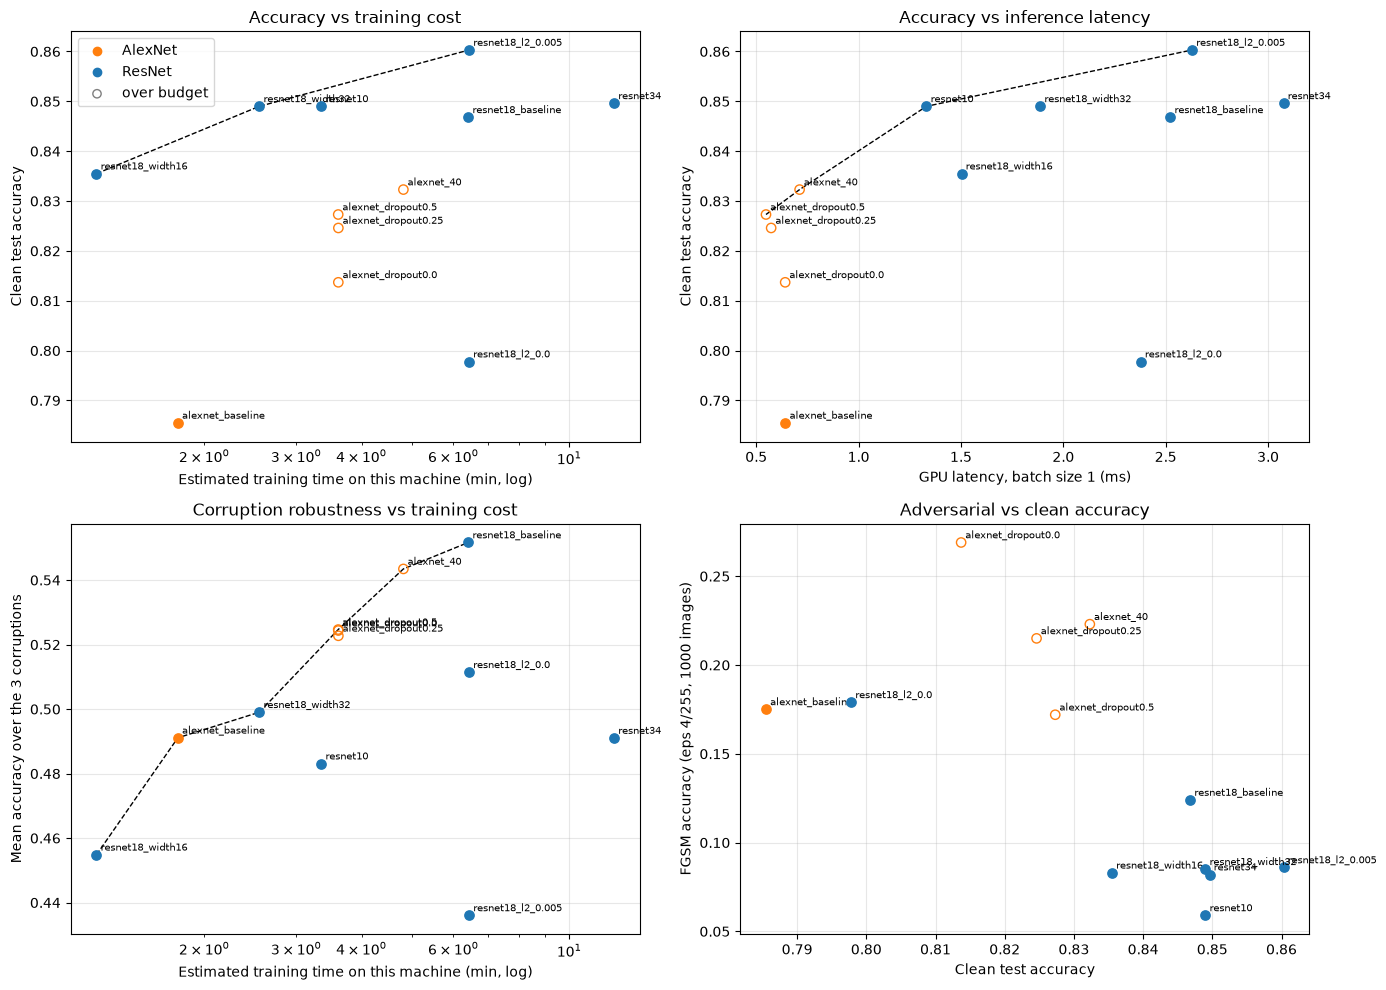

In [7]:
def pareto(df, cost, score):
    # keeps the points where nothing else is both cheaper and better
    df = df.dropna(subset=[cost, score]).sort_values([cost, score], ascending=[True, False])
    front, best = [], -np.inf
    for name, row in df.iterrows():
        if row[score] > best:
            front.append(name); best = row[score]
    return df.loc[front]


COLOURS = {"AlexNet": "tab:orange", "ResNet": "tab:blue"}


def scatter(ax, x, y, title, xlabel, ylabel, logx=False, front=True):
    for name, row in bench.iterrows():
        colour = COLOURS[row.family]
        ax.scatter(row[x], row[y], s=45, color=colour if row.in_budget else "none", edgecolors=colour, zorder=3)
        ax.annotate(name, (row[x], row[y]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    if front:
        f = pareto(bench, x, y)
        ax.plot(f[x], f[y], "k--", lw=1, zorder=2)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    if logx:
        ax.set_xscale("log")
    ax.grid(alpha=0.3)


latency = "gpu_latency_ms" if bench.gpu_latency_ms.notna().any() else "cpu_latency_ms"
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
scatter(axes[0, 0], "est_run_min_here", "test_clean", "Accuracy vs training cost",
        f"Estimated training time on this machine (min, log)", "Clean test accuracy", logx=True)
scatter(axes[0, 1], latency, "test_clean", "Accuracy vs inference latency",
        f"{latency.split('_')[0].upper()} latency, batch size 1 (ms)", "Clean test accuracy")
scatter(axes[1, 0], "est_run_min_here", "corruption_mean", "Corruption robustness vs training cost",
        "Estimated training time on this machine (min, log)", "Mean accuracy over the 3 corruptions", logx=True)
scatter(axes[1, 1], "test_clean", "fgsm", "Adversarial vs clean accuracy",
        "Clean test accuracy", f"FGSM accuracy (eps 4/255, {N_ATTACK} images)", front=False)
for family, colour in COLOURS.items():
    axes[0, 0].scatter([], [], color=colour, label=family)
axes[0, 0].scatter([], [], color="none", edgecolors="grey", label="over budget")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "tradeoffs.png", dpi=150)
plt.show()

In [ ]:
# clean vs corrupted vs attacked accuracy for every model
cols = ["test_clean", "test_rotation", "test_elastic", "test_noise", "fgsm"]
order = bench.sort_values("test_clean").index
ax = bench.loc[order, cols].rename(columns=lambda c: c.replace("test_", "")).plot.barh(figsize=(10, 7), width=0.8)
ax.set(xlabel="Accuracy", title="Accuracy under each condition")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "robustness_bars.png", dpi=150); plt.show()

## Which model would we pick?

The budget is max 15 epochs and max the time ResNet-18 needs for 15 epochs on this machine. You can also add a latency limit if you want, e.g. if it had to run on a CPU one image at a time.

We pick on val accuracy, since picking on the test set would make the test result look better than it really is. We use two rules: the most accurate model in the budget, and the cheapest model within 1 point of that. With 5000 val images the standard error is about 0.5 points, so anything smaller than about 1 point is mostly noise.

In [8]:
BUDGET_MINUTES = None   # None = the time resnet18_baseline needs for 15 epochs here
MAX_LATENCY_MS = None   # e.g. 2.0 for a latency limit in ms, None = no limit
TOLERANCE = 0.01        # "nearly as good" = within 1 point of the best val accuracy

if BUDGET_MINUTES is not None:
    budget = BUDGET_MINUTES
elif "resnet18_baseline" in bench.index:
    budget = bench.loc["resnet18_baseline", "est_budget_min_here"]
else:
    budget = bench.est_budget_min_here.max()
feasible = bench[bench.in_budget & (bench.est_run_min_here <= budget * 1.001)]
if MAX_LATENCY_MS is not None:
    feasible = feasible[feasible[latency] <= MAX_LATENCY_MS]

ranked = feasible.sort_values("val_accuracy", ascending=False)
display(ranked[["change", "est_run_min_here", latency, "parameters", "val_accuracy", "test_clean",
                "corruption_mean", "fgsm"]].round(4))

best = ranked.index[0]
near = ranked[ranked.val_accuracy >= ranked.val_accuracy.iloc[0] - TOLERANCE]
cheap = near.est_run_min_here.idxmin()
print(f"budget: {BUDGET_EPOCHS} epochs and {budget:.1f} min on {HARDWARE}")
print(f"most accurate within budget: {best} (val {bench.loc[best, 'val_accuracy']:.4f}, test {bench.loc[best, 'test_clean']:.4f})")
print(f"cheapest within {TOLERANCE:.0%} of that: {cheap} (val {bench.loc[cheap, 'val_accuracy']:.4f}, "
      f"{bench.loc[cheap, 'est_run_min_here']:.1f} vs {bench.loc[best, 'est_run_min_here']:.1f} min, "
      f"{bench.loc[cheap, latency]:.2f} vs {bench.loc[best, latency]:.2f} ms)")

,change,est_run_min_here,gpu_latency_ms,parameters,val_accuracy,test_clean,corruption_mean,fgsm
run,,,,,,,,
resnet18_baseline,ResNet-18 baseline,6.4049,2.5228,11173962,0.8552,0.8468,0.5517,0.124
resnet18_width32,"ResNet-18, width 32",2.5487,1.8872,2797610,0.8542,0.8490,0.4990,0.085
resnet10,ResNet-10 (1 block per stage),3.3496,1.3316,4903242,0.8502,0.8490,0.4831,0.059
resnet18_width16,"ResNet-18, width 16",1.2428,1.5028,701466,0.8456,0.8355,0.4548,0.083
alexnet_baseline,AlexNet baseline,1.7791,0.6423,6976842,0.7896,0.7855,0.4911,0.175


budget: 15 epochs and 6.4 min on NVIDIA GeForce RTX 3060 Laptop GPU
most accurate within budget: resnet18_baseline (val 0.8552, test 0.8468)
cheapest within 1% of that: resnet18_width16 (val 0.8456, 1.2 vs 6.4 min, 1.50 vs 2.52 ms)


## Which changes are worth it?

Each change compared to its reference run. The cost columns are relative, so +100% means twice the cost.

`clear_change` is True if the test accuracy difference is bigger than about 1 point, which is roughly what you can trust with 10k test images. FGSM only uses 1000 images so the differences there need to be around 3 points before they mean much.

In [9]:
def se(p, n):
    return np.sqrt(p * (1 - p) / n)


rows = []
for name, row in bench.iterrows():
    ref = row.reference
    if not isinstance(ref, str) or ref not in bench.index:
        continue
    r = bench.loc[ref]
    noise_test = 1.96 * np.sqrt(se(row.test_clean, 10_000) ** 2 + se(r.test_clean, 10_000) ** 2)
    rows.append({
        "run": name, "vs": ref, "change": row.change,
        "Δ val acc": row.val_accuracy - r.val_accuracy,
        "Δ test acc": row.test_clean - r.test_clean,
        "Δ corruption mean": row.corruption_mean - r.corruption_mean,
        "Δ fgsm": row.fgsm - r.fgsm,
        "Δ train time %": 100 * (row.est_run_min_here / r.est_run_min_here - 1),
        f"Δ {latency.split('_')[0]} latency %": 100 * (row[latency] / r[latency] - 1),
        "Δ params %": 100 * (row.parameters / r.parameters - 1),
        "clear_change": abs(row.test_clean - r.test_clean) > noise_test,
    })
changes = pd.DataFrame(rows).set_index("run")
display(changes.round(3))
changes.to_csv(RESULTS_DIR / "task6_changes.csv")

,vs,change,Δ val acc,Δ test acc,Δ corruption mean,Δ fgsm,Δ train time %,Δ gpu latency %,Δ params %,clear_change
run,,,,,,,,,,
resnet18_baseline,alexnet_baseline,ResNet-18 baseline,0.066,0.061,0.061,-0.051,260.009,292.753,60.158,True
alexnet_40,alexnet_baseline,"AlexNet, 40 epochs",0.052,0.047,0.052,0.048,170.402,10.813,0.000,True
alexnet_dropout0.0,alexnet_dropout0.5,"AlexNet, no dropout (30 ep)",-0.008,-0.014,-0.000,0.097,0.051,17.108,0.000,True
alexnet_dropout0.25,alexnet_dropout0.5,"AlexNet, dropout 0.25 (30 ep)",0.001,-0.003,-0.002,0.043,0.070,4.604,0.000,False
alexnet_dropout0.5,alexnet_baseline,"AlexNet, dropout 0.5 (30 ep)",0.045,0.042,0.034,-0.003,102.843,-14.738,0.000,True
resnet18_l2_0.0,resnet18_baseline,"ResNet-18, no weight decay",-0.051,-0.049,-0.040,0.055,0.320,-5.736,0.000,True
resnet18_l2_0.005,resnet18_baseline,"ResNet-18, weight decay 5e-3",0.013,0.013,-0.116,-0.038,0.351,4.200,0.000,True
resnet18_width16,resnet18_baseline,"ResNet-18, width 16",-0.010,-0.011,-0.097,-0.041,-80.597,-40.429,-93.722,True
resnet18_width32,resnet18_baseline,"ResNet-18, width 32",-0.001,0.002,-0.053,-0.039,-60.208,-25.191,-74.963,False


## How sensitive are the results?

### Training length

Because of the cosine schedule, the val accuracy at epoch 5 of a 15 epoch run isn't what you'd get from a 5 epoch run (the lr hasn't gone down yet). So these curves mostly show how fast each model learns. The proper comparison is `alexnet_40` vs `alexnet_baseline`, which is the same setup just trained for longer.

The x-axis is the recorded training time, so it depends on which laptop trained each run.

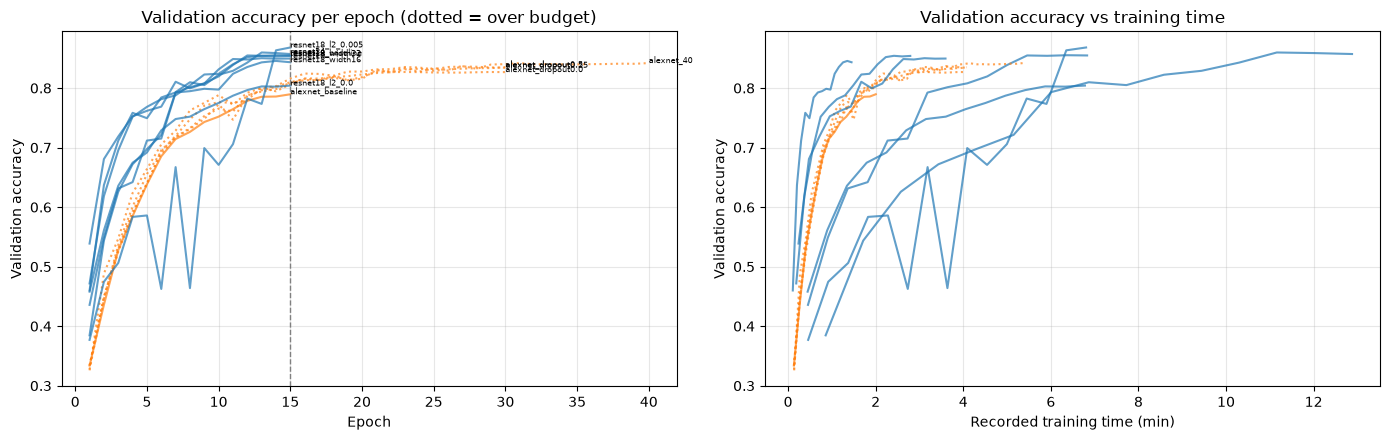

,val@5,val@10,val@15,val@final,rank_val@5,rank_val@10,rank_val@15,rank_val@final
resnet18_l2_0.005,0.5860,0.6992,0.8682,0.8682,12,12,1,1
resnet34,0.6974,0.8224,0.8598,0.8598,5,3,2,2
resnet18_baseline,0.7118,0.8196,0.8552,0.8552,4,4,3,3
resnet18_width32,0.7684,0.8240,0.8542,0.8542,1,2,4,4
resnet10,0.7618,0.8314,0.8502,0.8502,2,1,5,5
resnet18_width16,0.7584,0.7988,0.8456,0.8456,3,5,6,6
alexnet_40,0.6386,0.7656,0.8090,0.8420,10,10,9,7
alexnet_dropout0.25,0.6556,0.7764,0.8160,0.8362,8,7,7,8
alexnet_dropout0.5,0.6412,0.7726,0.8098,0.8350,9,9,8,9
alexnet_dropout0.0,0.6640,0.7882,0.8064,0.8270,7,6,10,10


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in runs.items():
    h = pd.DataFrame(r["history"])
    style = "-" if r["config"]["epochs"] <= BUDGET_EPOCHS else ":"
    colour = COLOURS[overview.loc[name, "family"]]
    axes[0].plot(h.epoch, h.val_accuracy, style, color=colour, alpha=0.7)
    axes[0].annotate(name, (h.epoch.iloc[-1], h.val_accuracy.iloc[-1]), fontsize=6)
    axes[1].plot(h.epoch_seconds.cumsum() / 60, h.val_accuracy, style, color=colour, alpha=0.7)
axes[0].axvline(BUDGET_EPOCHS, color="grey", lw=1, ls="--")
axes[0].set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy per epoch (dotted = over budget)")
axes[1].set(xlabel="Recorded training time (min)", ylabel="Validation accuracy", title="Validation accuracy vs training time")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "duration.png", dpi=150); plt.show()

# rank of each run (by val accuracy) after 5, 10 and 15 epochs
checkpoints_at = [5, 10, 15]
at_epoch = pd.DataFrame({f"val@{e}": {name: max(h["val_accuracy"] for h in r["history"] if h["epoch"] <= e)
                                      for name, r in runs.items()} for e in checkpoints_at})
at_epoch["val@final"] = robustness.val_accuracy
ranks = at_epoch.rank(ascending=False).astype(int).add_prefix("rank_")
display(at_epoch.round(4).join(ranks).sort_values("val@final", ascending=False))

### Seed

Everything was trained with seed 42, so we only have one run of each. The binomial standard error gives an idea of the noise, but the real noise is bigger since it doesn't include differences from weight init and batch order.

If there are checkpoints with other seeds they get picked up below. Set `RUN_SEED_CHECK = True` to train a few configs with seeds 0 and 1 (it prints roughly how long it'll take first).

In [13]:
print(f"standard error of test accuracy (10,000 images) at 85%: ±{100 * se(0.85, 10_000):.2f} points")
print(f"standard error of val accuracy (5,000 images) at 85%:   ±{100 * se(0.85, 5_000):.2f} points")
print(f"standard error of FGSM accuracy ({N_ATTACK} images) at 15%:  ±{100 * se(0.15, N_ATTACK):.2f} points")

RUN_SEED_CHECK = False
SEED_CHECK_RUNS = ["alexnet_baseline", "resnet18_baseline", "resnet18_width32"]
EXTRA_SEEDS = [0, 1]

todo = [(n, s) for n in SEED_CHECK_RUNS if n in runs for s in EXTRA_SEEDS
        if not (CHECKPOINT_DIR / f"{n}_seed{s}.pt").exists()]
if todo:
    minutes = sum(bench.loc[n, "est_run_min_here"] for n, _ in todo)
    print(f"\nseed check: {len(todo)} runs to train, roughly {minutes:.0f}+ min on this machine "
          f"(compute only, data loading adds more)")
if RUN_SEED_CHECK:
    for name, seed in todo:
        config = dict(runs[name]["config"], seed=seed)
        run_experiment(Run(**config), CONFIGS[name][0], data, split, device, num_workers=NUM_WORKERS)

seed_rows = []
for name, (model_class, *_ ) in CONFIGS.items():
    for path in sorted(CHECKPOINT_DIR.glob(f"{name}_seed*.pt")):
        seed = int(path.stem.rsplit("_seed", 1)[1])
        r = runs[name] if seed == SEED and name in runs else load_checkpoint(name, model_class, seed)
        seed_rows.append({"run": name, "seed": seed, "val_accuracy": r["summary"]["best_val_accuracy"],
                          "test_clean": (predict(r["model"].to(device).eval(), clean) == labels).float().mean().item()})
        r["model"].cpu()
seeds = pd.DataFrame(seed_rows)
multi = seeds.groupby("run").filter(lambda g: len(g) > 1)
if len(multi):
    summary = multi.groupby("run")[["val_accuracy", "test_clean"]].agg(["mean", "std", "count"])
    display(summary.round(4))
    summary.to_csv(RESULTS_DIR / "task6_seeds.csv")
else:
    print("\nonly one seed per configuration so far")

standard error of test accuracy (10,000 images) at 85%: ±0.36 points
standard error of val accuracy (5,000 images) at 85%:   ±0.50 points
standard error of FGSM accuracy (1000 images) at 15%:  ±1.13 points

seed check: 6 runs to train, roughly 21+ min on this machine (compute only, data loading adds more)

only one seed per configuration so far


### Hardware

We check three things here. First, the seconds per epoch from the two GPUs we trained on, to see if the ResNet/AlexNet cost ratio changes between machines. Some of it is probably data loading, which takes about the same time for both models. Second, whether the order of the models by latency changes between GPU and CPU. Third, how reproducible training is: `resnet18_baseline` and `resnet18_l2_0.0005` are the same setup so we compare their predictions, and the test accuracies Task 2 and Task 4 got for "the same" baselines are copied in too.

In [11]:
# 1. seconds per epoch recorded on two machines (copied from the task 2 and 4 outputs) vs the speed test here
OTHER_MACHINES = pd.DataFrame({
    "RTX 3060 Laptop (Task 2, recorded)": {"alexnet_baseline": 8.01, "resnet18_baseline": 27.32},
    "RTX 4070 (Task 4, recorded)":        {"alexnet_baseline": 21.19, "resnet18_baseline": 33.80},
})
OTHER_MACHINES[f"{HARDWARE} (speed test, compute only)"] = training_cost.est_s_per_epoch_here
hw = OTHER_MACHINES.loc[["alexnet_baseline", "resnet18_baseline"]].T
hw["ResNet / AlexNet"] = hw.resnet18_baseline / hw.alexnet_baseline
display(hw.round(2))

# 2. does the latency order change between gpu and cpu?
if inference.gpu_latency_ms.notna().all():
    lat = inference[["gpu_latency_ms", "cpu_latency_ms"]].copy()
    lat["gpu_rank"] = lat.gpu_latency_ms.rank().astype(int)
    lat["cpu_rank"] = lat.cpu_latency_ms.rank().astype(int)
    display(lat.sort_values("cpu_rank").round(3))
    print("Spearman correlation of GPU and CPU latency rankings:",
          round(lat.gpu_latency_ms.corr(lat.cpu_latency_ms, method="spearman"), 3))

# 3. same settings trained twice
REPORTED = pd.DataFrame({
    "Task 2 (RTX 3060 Laptop)": {"alexnet_baseline": 0.7855, "resnet18_baseline": 0.8468},
    "Task 4/5 (RTX 4070)":      {"alexnet_baseline": 0.7852, "resnet18_baseline": 0.8481},
})
REPORTED["this checkpoint"] = robustness.test_clean
print("\nclean test accuracy of the 'same' baseline from different runs:")
display(REPORTED.round(4))

twin = load_checkpoint("resnet18_l2_0.0005", ResNet18)
if twin is not None and "resnet18_baseline" in runs:
    a = predict(runs["resnet18_baseline"]["model"].to(device).eval(), clean)
    b = predict(twin["model"].to(device).eval(), clean)
    print(f"resnet18_baseline vs resnet18_l2_0.0005: test acc {(a == labels).float().mean():.4f} vs "
          f"{(b == labels).float().mean():.4f}, predictions agree on {(a == b).float().mean():.2%} of test images")
    runs["resnet18_baseline"]["model"].cpu()
else:
    print("resnet18_l2_0.0005 checkpoint not here, skipping the twin comparison")

,alexnet_baseline,resnet18_baseline,ResNet / AlexNet
"RTX 3060 Laptop (Task 2, recorded)",8.01,27.32,3.41
"RTX 4070 (Task 4, recorded)",21.19,33.80,1.60
"NVIDIA GeForce RTX 3060 Laptop GPU (speed test, compute only)",7.12,25.62,3.60


,gpu_latency_ms,cpu_latency_ms,gpu_rank,cpu_rank
run,,,,
resnet18_width16,1.503,1.211,7,1
alexnet_40,0.712,2.229,5,2
alexnet_baseline,0.642,2.247,4,3
alexnet_dropout0.0,0.641,2.319,3,4
resnet18_width32,1.887,2.647,8,5
alexnet_dropout0.25,0.573,3.027,2,6
alexnet_dropout0.5,0.548,3.387,1,7
resnet10,1.332,3.755,6,8
resnet18_baseline,2.523,6.989,10,9


Spearman correlation of GPU and CPU latency rankings: 0.601

clean test accuracy of the 'same' baseline from different runs:


,Task 2 (RTX 3060 Laptop),Task 4/5 (RTX 4070),this checkpoint
alexnet_baseline,0.7855,0.7852,0.7855
resnet18_baseline,0.8468,0.8481,0.8468


resnet18_baseline vs resnet18_l2_0.0005: test acc 0.8468 vs 0.8468, predictions agree on 100.00% of test images


## Discussion

*Drafts based on the Task 2-5 numbers, check them against the tables above after running.*

### Which model would we pick, and why?

Under the 15 epoch budget the ResNets are a lot more accurate than AlexNet (85.5% vs 79.0% val), even though AlexNet is around 3x faster per epoch on the 3060. But the plain ResNet-18 isn't really the best option:

- Weight decay 5e-3 got 86.8% val for the same cost, so that's basically free.
- Augmentation got 90.1% clean test vs 84.8%, and only costs a bit more training time since it runs on the CPU.
- Width 32 got 85.4% vs 85.5% with 4x fewer parameters and about 2.4x less time per epoch.

So we'd pick ResNet-18 with augmentation (probably with the higher weight decay too, but we didn't test them together). If cost matters more, width 32 is the better deal. [check against the output above]

### Which changes improve accuracy or robustness at an acceptable cost?

Weight decay, augmentation and the narrower ResNet are all worth it. ResNet-34 isn't, it's about 1.9x the cost for +0.5 points which is within the noise. ResNet-10 is about half the cost of ResNet-18 for -0.5 points, so it's a decent cheap option too. Dropout only helped AlexNet a little (82.7% to around 83.5%), it mostly stopped the val loss going up.

For robustness, nothing came for free. Augmentation helped a lot with elastic but made ResNet-18 worse on rotation (33.5% to 24.4%) and noise (51.4% to 33.8%), so it only really helps with corruptions that look like the augmentation. And all the models basically fall apart under FGSM (17% AlexNet, 10% ResNet-18), with the more accurate model actually being less robust. To fix that you'd need something like adversarial training, which is a lot more expensive.

### Which conclusions are sensitive to the training duration, random seed, or hardware?

Training length: ResNet beating AlexNet is partly because of the short budget. With 40 epochs AlexNet went from 79.0% to 84.2%, which is close to ResNet-18 at 15 epochs. AlexNet was still improving at epoch 15 while ResNet already had 100% train accuracy.

Seed: a lot of the ResNet differences are smaller than the noise. Width 32, ResNet-10, ResNet-18 and ResNet-34 are all within about 1 point of each other, so their order could easily change with another seed. The bigger effects like ResNet vs AlexNet, augmentation and weight decay should still hold.

Hardware: ResNet-18 was 3.4x slower than AlexNet per epoch on the 3060 but only 1.6x slower on the 4070 run, so any "X times cheaper" claim depends on the machine. That's why everything here is measured on one machine. Accuracy also changes a little between GPUs, the same ResNet-18 baseline got 84.68% in Task 2 and 84.81% in Task 4.

### What further experiment would give the most useful evidence?

Running the main configs with 3-5 seeds. Most of the close calls are within the noise of one run, so means and standard deviations would show which differences are actually real. After that it'd be worth trying the best changes together (augmentation + weight decay 5e-3, at width 32 and 64), since we only ever changed one thing at a time.